<a href="https://colab.research.google.com/github/andreasantalla/ASE-GIS/blob/main/ps3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# [ps3] manipulating data and merging
## Class notes

* make histogram of main variable to see distribution
* be clear about measurement -- always include in note/caption/interpretation
* ideally, map multiple measures of the same thing, i.e., "triangulate"
* standardize to get meaningful interpretations -- "per sq km" or "pop per capita"
* useful: side-by-side, overlays, annotations, classification method

## Notes for PS2 -> PS3
for healthcare maps
* add Sonrisa location

for education maps
* map multiple measures of the same thing
  * add map with data for not just Spanish speakers
  * add years since arrival map
* focus on interpretation
  * nonlinear relationship
  * association with latino immigrants
* make scatterplot only south philly census tracts
* raster pictures to compare different neighbourhoods (Lower Moyamensing vs Passyunk Square)

**Why this data?** These maps show where Comunidad Garces’s services are most needed. Each map pairs a need (no health insurance, limited English, no home computer, or no high school diploma) with income, since low-income areas are least able to pay for other options. The circles show where immigrants live, which is who the organization mainly serves.

## **Load Packages**

In [34]:
## ===== Imports =====
import os, zipfile
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from shapely.geometry import Point
import mapclassify
import numpy as np
!pip install adjustText -q
import textwrap
import matplotlib.patheffects as pe
from adjustText import adjust_text
import requests
import json
import folium
import io
import pandas as pd
from PIL import Image

In [3]:
#!python --version
gpd.__version__

'1.2.0'

##  **Load 2015- and 2020-vintage Philly tracts**

Philadelphia 2015-vintage tract count: 384


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

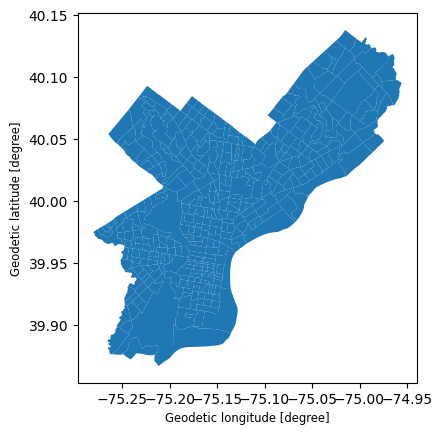

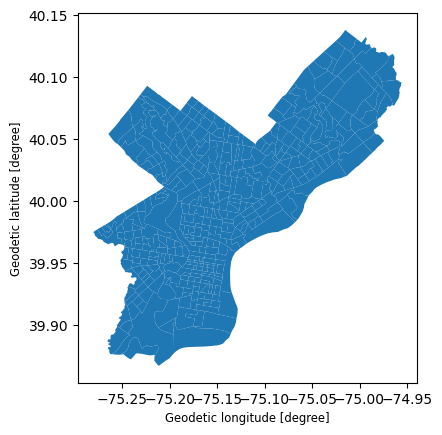

In [4]:
# ===== Load 2015-vintage Philly tracts (matches CDC PLACES em5e-5hvn boundary vintage) =====
!wget -q -O phl_tracts_2015.zip "https://github.com/andreasantalla/ASE-GIS/raw/refs/heads/main/tl_2015_42_tract.zip"
zipfile.ZipFile('phl_tracts_2015.zip', 'r').extractall()

pa_tracts_2015 = gpd.read_file('tl_2015_42_tract.shp')
phT_2015 = pa_tracts_2015[pa_tracts_2015['COUNTYFP'] == '101'][['GEOID', 'NAME', 'geometry']].copy()
phT_2015['GEOID'] = phT_2015['GEOID'].astype(str)
phT_2015.plot()  # sanity check
print(f"Philadelphia 2015-vintage tract count: {len(phT_2015)}")  # should be 384


## ===== Load 2020-vintage Philly tracts (matches ACS 2022 5-year boundaries) =====
!wget -q -O phl_tracts_2020.zip "https://www2.census.gov/geo/tiger/TIGER2020/TRACT/tl_2020_42_tract.zip"
zipfile.ZipFile('phl_tracts_2020.zip', 'r').extractall()

pa_tracts = gpd.read_file('tl_2020_42_tract.shp')
phT = pa_tracts[pa_tracts['COUNTYFP'] == '101'][['GEOID', 'NAME', 'geometry']].copy()
phT['GEOID'] = phT['GEOID'].astype(str)
phT.plot()  # sanity check: should look like Philadelphia

## **Reusable functions**

In [5]:
## ===== Reusable ACS pull function (from GitHub instead of Census API) =====
def pull_acs_table_from_github(url, variables, fname):
    """Downloads a pre-saved ACS JSON from GitHub, returns a tidy dataframe with GEOID."""
    os.system(f'wget -q -O {fname} "{url}"')

    df = pd.read_json(fname)
    df.columns = df.iloc[0]
    df = df[1:].reset_index(drop=True)
    for col in variables:
        df[col] = pd.to_numeric(df[col])
    df['GEOID'] = df['state'] + df['county'] + df['tract']
    return df

In [6]:
## ===== Reusable mapping function =====
def plot_lep_choropleth(gdf, column, title, legend_title, no_data_label, point_lon, point_lat):
    """Plots a choropleth with a red point overlay, gray hatching for missing data, and dual legends."""
    gdf_4326 = gdf.to_crs(epsg=4326)
    valid = gdf_4326.dropna(subset=[column])
    missing = gdf_4326[gdf_4326[column].isna()]

    print(f"Missing: {len(missing)} of {len(gdf_4326)} tracts")

    fig, ax = plt.subplots(1, figsize=(6, 10))

    missing.plot(ax=ax, color='lightgray', edgecolor='black', linewidth=0.5, hatch='///')
    valid.plot(column=column, cmap='RdYlGn_r', scheme='natural_breaks', k=5,
               legend=True, ax=ax, edgecolor='black', linewidth=0.5)

    choropleth_legend = ax.get_legend()
    choropleth_legend.set_title(legend_title)
    choropleth_legend.set_bbox_to_anchor((1.05, 1))

    ax.scatter(point_lon, point_lat, marker='o', color='red', s=60, zorder=5)
    ax.set_title(title)
    ax.axis('off')

    ax.add_artist(choropleth_legend)
    point = Line2D([0], [0], label='Comunidad Garces', marker='o', markersize=8,
                   markeredgecolor='r', markerfacecolor='r', linestyle='')
    no_data = Line2D([0], [0], label=no_data_label, marker='s', markersize=8,
                      markerfacecolor='lightgray', markeredgecolor='black', linestyle='')
    ax.legend(handles=[point, no_data], loc='lower right')

    plt.show()

In [7]:
## ===== Comunidad Garces location =====
garces_lat, garces_lon = 39.9249, -75.1601
garces_point = gpd.GeoSeries([Point(garces_lon, garces_lat)], crs='EPSG:4326')
garces_point_proj = garces_point.to_crs(epsg=2272)   # PA State Plane, feet
buffer_1mi = garces_point_proj.buffer(5280).to_crs(epsg=4326)  # 1 mile

In [8]:
## ===== Reusable bubble overlay =====
def add_foreign_born_bubbles(ax, gdf_4326, col='pct_foreign_born', scale=3, zorder=4):
    """Proportional circles at tract centroids, sized by % foreign-born."""
    g = gdf_4326.dropna(subset=[col]).copy()
    cent = g.to_crs(epsg=2272).centroid.to_crs(epsg=4326)   # centroids in projected CRS
    ax.scatter(cent.x, cent.y, s=g[col] * scale, facecolor='white', alpha=0.55,
               edgecolor='black', linewidth=0.6, zorder=zorder)

def foreign_born_legend_handles(scale=3, levels=(5, 20, 40)):
    # scatter's s is area in pt^2, Line2D's markersize is a diameter in pt -> sqrt
    return [Line2D([0], [0], marker='o', linestyle='', markerfacecolor='white',
                   markeredgecolor='black', markersize=np.sqrt(v * scale),
                   label=f'{v}% foreign-born') for v in levels]

In [27]:
## ===== Reusable plotting function =====
def plot_tercile_bivariate(df, var, title, key_ylabel, ylabel):
    """Map 2 clone: tercile-classified `var` x HUD AMI income band, with buffer, bubbles, neighborhoods, scatter."""
    d = df.to_crs(epsg=4326)
    valid = d.dropna(subset=[var, 'median_hh_income']).copy()
    missing = d[d[var].isna() | d['median_hh_income'].isna()]

    q33, q66 = valid[var].quantile([0.33, 0.66])
    valid['var_class'] = np.select([valid[var] < q33, valid[var] < q66], [0, 1], default=2)
    valid['income_class'] = np.select([valid['median_hh_income'] < 57350,
                                       valid['median_hh_income'] < 91750], [0, 1], default=2)
    valid['biv_color'] = valid.apply(
        lambda r: bivariate_colors[(r['income_class'], r['var_class'])], axis=1)

    xlim = (garces_lon - 0.025, garces_lon + 0.045)
    ylim = (garces_lat - 0.02, garces_lat + 0.03)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={'width_ratios': [1, 0.9]})

    missing.plot(ax=ax, color='lightgray', edgecolor='black', linewidth=0.5, hatch='///')
    valid.plot(ax=ax, color=valid['biv_color'], edgecolor='black', linewidth=0.4)
    add_foreign_born_bubbles(ax, valid, scale=3)

    buffer_1mi.plot(ax=ax, color='none', edgecolor='blue', linewidth=1.8, linestyle='--', zorder=4)
    ax.scatter(garces_lon, garces_lat, marker='o', color='yellow', s=90, zorder=5, edgecolor='black')
    add_neighborhood_labels(ax, xlim, ylim, names=keep)
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    ax.set_title(title)
    ax.axis('off')

    point = Line2D([0], [0], label='Comunidad Garces', marker='o', markersize=8,
                   markeredgecolor='black', markerfacecolor='yellow', linestyle='')
    buffer_handle = Line2D([0], [0], label='1-mile radius', color='blue', linewidth=1.8, linestyle='--')
    neigh_handle = Line2D([0], [0], label='Neighborhood boundary', color='black', linewidth=1.2)
    no_data = Line2D([0], [0], label='Special land use', marker='s', markersize=8,
                     markerfacecolor='lightgray', markeredgecolor='black', linestyle='')
    ax.legend(handles=[point, buffer_handle, neigh_handle, no_data] + foreign_born_legend_handles(scale=3),
              loc='lower right', fontsize=6)

    legend_ax = ax.inset_axes([0.78, 0.55, 0.20, 0.20])
    for i in range(3):
        for v in range(3):
            legend_ax.add_patch(plt.Rectangle((i, v), 1, 1, color=bivariate_colors[(i, v)]))
    legend_ax.set_xlim(0, 3); legend_ax.set_ylim(0, 3)
    legend_ax.set_xticks([]); legend_ax.set_yticks([])
    legend_ax.set_xlabel('<50% | 50-80% | >80%\nAMI', fontsize=6)
    legend_ax.set_ylabel(key_ylabel, fontsize=6)
    legend_ax.set_title('Bivariate Key', fontsize=9)

    view = valid.cx[xlim[0]:xlim[1], ylim[0]:ylim[1]]     # tracts that appear in the zoomed map
    add_scatter(ax2, view, var, ylabel, hlines=(q33, q66),
                title=f'Income vs. {ylabel.replace("% ", "")}, Tracts on Map (n={len(view)})')
    plt.show()

    print(f"Tercile cutoffs for {var}: 33rd = {q33:.1f}%, 66th = {q66:.1f}%")
    for c, lab in [(0, 'Low'), (1, 'Mid'), (2, 'High')]:
        s = valid[valid['var_class'] == c][var]
        print(f"  {lab}: n={len(s)}, range {s.min():.1f}%-{s.max():.1f}%, mean {s.mean():.1f}%")
    return valid, missing

In [10]:
## ===== Reusable scatterplot function =====
def add_scatter(ax2, valid, var, ylabel, hlines, title):
    """Income vs `var` scatter, colored like the map. hlines = class cutoffs for `var`."""
    in_buffer = valid.intersects(buffer_1mi.iloc[0])

    ax2.scatter(valid['median_hh_income'], valid[var],
                c=valid['biv_color'], s=15 + valid['pct_foreign_born'].fillna(0) * 1.5,
                edgecolor=np.where(in_buffer, 'blue', 'black'),
                linewidth=np.where(in_buffer, 1.5, 0.4), alpha=0.9)

    for x in (57350, 91750):
        ax2.axvline(x, color='gray', linestyle='--', linewidth=0.8)
    for y in hlines:
        ax2.axhline(y, color='gray', linestyle=':', linewidth=0.8)

    ax2.set_xlabel('Median household income ($)')
    ax2.set_ylabel(ylabel)
    ax2.set_title(f'{title}\n(blue outline = within 1 mile; size = % foreign-born)', fontsize=9)
    ax2.xaxis.set_major_formatter(lambda x, _: f'${x/1000:.0f}k')
    plt.tight_layout()

## **Pull the ACS + the CDC PLACES data**

In [11]:
acs_lep_hh = pull_acs_table_from_github(
    url="https://raw.githubusercontent.com/andreasantalla/ASE-GIS/refs/heads/main/acs5_householdLEP.json",
    variables=['C16002_001E', 'C16002_003E'],
    fname="acs_lep_hh.json"
)
acs_lep_hh['pct_lep_spanish_hh'] = np.where(
    acs_lep_hh['C16002_001E'] > 0,
    100 * acs_lep_hh['C16002_003E'] / acs_lep_hh['C16002_001E'],
    np.nan  # or 0, if you want to treat "no households" as "0% LEP" rather than "undefined"
)

acs_income = pull_acs_table_from_github(
    url="https://raw.githubusercontent.com/andreasantalla/ASE-GIS/refs/heads/main/acs5_income.json",
    variables=['B19013_001E'],
    fname="acs_income.json"
)
acs_income = acs_income.rename(columns={'B19013_001E': 'median_hh_income'})

acs_income_2015 = pull_acs_table_from_github(
    url="https://raw.githubusercontent.com/andreasantalla/ASE-GIS/refs/heads/main/acs5_income_2015.json",
    variables=['B19013_001E'],
    fname="acs_income_2015.json"
)
acs_income_2015 = acs_income_2015.rename(columns={'B19013_001E': 'median_hh_income'})
for df in (acs_income, acs_income_2015):
    df.loc[df['median_hh_income'] < 0, 'median_hh_income'] = np.nan

def pull_places_from_api(county_fips, measure_id, release_resource="em5e-5hvn"):
    # Queries CDC PLACES census-tract-level data from the Socrata API.
    # release_resource "em5e-5hvn" = PLACES Census Tract Data, 2023 release (opendata format)
    # Returns a tidy dataframe with GEOID (=LocationID, 11-digit tract FIPS) and the measure value.
    url = (f"https://data.cdc.gov/resource/{release_resource}.json"
           f"?countyfips={county_fips}&measureid={measure_id}&$limit=500")
    df = pd.read_json(url)
    df = df.rename(columns={'locationid': 'GEOID', 'data_value': measure_id.lower()})
    df['GEOID'] = df['GEOID'].astype(str)
    df[measure_id.lower()] = pd.to_numeric(df[measure_id.lower()], errors='coerce')
    return df[['GEOID', measure_id.lower(), 'totalpopulation']]

    # Pull % uninsured adults (ACCESS2) for Philadelphia County (FIPS 42101)
places_uninsured = pull_places_from_api(county_fips="42101", measure_id="ACCESS2")
places_uninsured = places_uninsured.rename(columns={'access2': 'pct_uninsured'})

# ===== % foreign-born (immigrants as share of total population) =====
def add_pct_foreign_born(df):
    df['pct_foreign_born'] = np.where(df['B05002_001E'] > 0,
                                      100 * df['B05002_013E'] / df['B05002_001E'],
                                      np.nan)   # undefined where population = 0
    return df

acs_fb = pull_acs_table_from_github(
    url="https://raw.githubusercontent.com/andreasantalla/ASE-GIS/refs/heads/main/acs5_popimm2022.json",
    variables=['B05002_001E', 'B05002_013E'], fname="acs_fb_2022.json")
acs_fb = add_pct_foreign_born(acs_fb)

acs_fb_2015 = pull_acs_table_from_github(
    url="https://raw.githubusercontent.com/andreasantalla/ASE-GIS/refs/heads/main/acs5_popimm2015.json",
    variables=['B05002_001E', 'B05002_013E'], fname="acs_fb_2015.json")
acs_fb_2015 = add_pct_foreign_born(acs_fb_2015)

# ===== Digital literacy proxy: % households with no computer =====
acs_dig = pull_acs_table_from_github(
    url="https://raw.githubusercontent.com/andreasantalla/ASE-GIS/refs/heads/main/acs5_digital.json",
    variables=['B28003_001E', 'B28003_006E'], fname="acs_digital.json")
acs_dig['pct_no_computer'] = np.where(acs_dig['B28003_001E'] > 0,
                                      100 * acs_dig['B28003_006E'] / acs_dig['B28003_001E'], np.nan)

# ===== GED need: % adults 25+ without HS diploma or equivalent =====
ged_vars = [f'B15003_{i:03d}E' for i in range(1, 17)]   # 001 = total, 002-016 = less than HS diploma
acs_ged = pull_acs_table_from_github(
    url="https://raw.githubusercontent.com/andreasantalla/ASE-GIS/refs/heads/main/acs5_GED.json",
    variables=ged_vars, fname="acs_ged.json")
less_hs = acs_ged[ged_vars[1:]].sum(axis=1)
acs_ged['pct_no_hs'] = np.where(acs_ged['B15003_001E'] > 0,
                                100 * less_hs / acs_ged['B15003_001E'], np.nan)

# Pull % uninsured adults (ACCESS2) for Philadelphia County (FIPS 42101)
places_uninsured = pull_places_from_api(county_fips="42101", measure_id="ACCESS2")
places_uninsured = places_uninsured.rename(columns={'access2': 'pct_uninsured'})

# Pull non-citizen coutns for Philadelphia County
acs_nc = pull_acs_table_from_github(
    url=("https://raw.githubusercontent.com/andreasantalla/ASE-GIS/refs/heads/main/acs5_noncitizen.json"),
    variables=['B05002_001E', 'B05002_013E', 'B05002_014E', 'B05002_021E'],
    fname="acs_noncitizen.json")



##Neighbourhoods

In [12]:
neigh = gpd.read_file(
    "https://raw.githubusercontent.com/opendataphilly/odp-data-storage/refs/heads/master/philadelphia-neighborhoods/philadelphia-neighborhoods.geojson"
).to_crs(epsg=4326)
neigh['label_pt'] = neigh.geometry.representative_point()

def stack(label, width=10):
    return textwrap.fill(label, width=width)

def add_neighborhood_labels(ax, xlim, ylim, names=None, name_col='MAPNAME', fontsize=6):
    neigh.plot(ax=ax, color='none', edgecolor='black', linewidth=1.2, zorder=3)

    in_view = neigh[neigh['label_pt'].apply(
        lambda p: xlim[0] < p.x < xlim[1] and ylim[0] < p.y < ylim[1])]
    if names is not None:
        in_view = in_view[in_view[name_col].isin(names)]

    texts = []
    for _, row in in_view.iterrows():
        t = ax.text(row['label_pt'].x, row['label_pt'].y, stack(row[name_col]),
                    ha='center', va='center', multialignment='center',
                    fontsize=fontsize, fontweight='bold', zorder=6, linespacing=0.9,
                    path_effects=[pe.withStroke(linewidth=2, foreground='white')])
        texts.append(t)
    return texts

keep = [
    # in/around the 1-mile buffer (the neighborhoods your interpretation talks about)
    'Passyunk Square', 'East Passyunk', 'Bella Vista', 'Newbold', 'Whitman',
    'Point Breeze', 'Pennsport', 'Queen Village', 'Dickinson Narrows',
    'Lower Moyamensing', 'Girard Estates', 'Hawthorne', 'Graduate Hospital',
    'West Passyunk', 'Packer Park', 'Greenwich',
    # orientation anchors
    'Rittenhouse', 'Society Hill', 'Old City', 'Riverfront', 'Washington Square West',
]

****
## **Map 1: Healthcare access need with buffer, annotation, zoom**
% adults aged 18-64 lacking health insurance, tract-level modeled estimates (CDC PLACES, ACCESS2)

No federal "safe harbor"-style threshold exists for insurance status (unlike Title VI's 5% LEP trigger),
so uninsured rate is classified using data-driven terciles (33rd/66th percentile splits) across Philly tracts.
Income classes remain the HUD FY2024 AMI bands used in Map 2, for comparability across both bivariate maps.

Professor comments: need to do outer with indicator on and investigate if merged correctly first when merging, then simplify the file to only relevant variables; maps also need 1-2 lines of interpretation.*See interpretation section for merging explanations.

In [13]:
# ===== Merge diagnostics for Map 1 (uninsured x income x foreign-born), on matching 2015-vintage tracts =====
check1 = phT_2015.merge(places_uninsured[['GEOID', 'pct_uninsured']], on='GEOID', how='outer', indicator=True)
print("Step 1 (2015-vintage tracts x uninsured):")
print(check1['_merge'].value_counts(), "\n")

check2 = check1.merge(acs_income_2015[['GEOID', 'median_hh_income']], on='GEOID', how='outer', indicator='_merge2')
print("Step 2 (+ 2015-vintage income):")
print(check2['_merge2'].value_counts(), "\n")

check3 = check2.merge(acs_fb_2015[['GEOID', 'pct_foreign_born']], on='GEOID', how='outer', indicator='_merge3')
print("Step 3 (+ 2015-vintage foreign-born):")
print(check3['_merge3'].value_counts(), "\n")

print("Right-only GEOIDs (should be empty or explainable):")
print("  step 2:", check2[check2['_merge2'] == 'right_only']['GEOID'].tolist())
print("  step 3:", check3[check3['_merge3'] == 'right_only']['GEOID'].tolist())

# ===== Merge + simplify (single pass) =====
biv2 = phT_2015.merge(places_uninsured[['GEOID', 'pct_uninsured']], on='GEOID', how='left')
biv2 = biv2.merge(acs_income_2015[['GEOID', 'median_hh_income']], on='GEOID', how='left')
biv2 = biv2.merge(acs_fb_2015[['GEOID', 'pct_foreign_born']], on='GEOID', how='left')
biv2 = biv2[['GEOID', 'geometry', 'pct_uninsured', 'median_hh_income', 'pct_foreign_born']]

# ===== Now derive valid/missing from the trimmed frame =====
biv2_4326 = biv2.to_crs(epsg=4326)
biv2_valid = biv2_4326.dropna(subset=['pct_uninsured', 'median_hh_income']).copy()
biv2_missing = biv2_4326[biv2_4326['pct_uninsured'].isna() | biv2_4326['median_hh_income'].isna()]

Step 1 (2015-vintage tracts x uninsured):
_merge
both          376
left_only       8
right_only      0
Name: count, dtype: int64 

Step 2 (+ 2015-vintage income):
_merge2
both          384
left_only       0
right_only      0
Name: count, dtype: int64 

Step 3 (+ 2015-vintage foreign-born):
_merge3
both          384
left_only       0
right_only      0
Name: count, dtype: int64 

Right-only GEOIDs (should be empty or explainable):
  step 2: []
  step 3: []


In [14]:
# ===== Categorize missing tracts: Map 1 (uninsured x income) =====

# Non-standard/special tract suffixes (parks, airports, industrial, water, etc.)
special_suffixes = ('9800', '9801', '9802', '9803', '9804', '9805')

def categorize_missing(missing_gdf, source_df, value_col, pop_threshold=200):
    """
    missing_gdf: rows from biv2_missing / biv_missing (has GEOID)
    source_df: the original pull (places_uninsured or acs_lep_hh) with population info, if available
    value_col: the variable that's missing (e.g. 'pct_uninsured')
    """
    df = missing_gdf[['GEOID']].copy()
    df['tract_code'] = df['GEOID'].str[5:]
    df['is_special_tract'] = df['tract_code'].str.startswith(('98', '99'))

    # Merge in population where we have it (PLACES has totalpopulation; ACS doesn't directly here)
    if 'totalpopulation' in source_df.columns:
        df = df.merge(source_df[['GEOID', 'totalpopulation']], on='GEOID', how='left')
        df['low_population'] = df['totalpopulation'] < pop_threshold
    else:
        df['totalpopulation'] = np.nan
        df['low_population'] = False

    def bucket(row):
        if row['is_special_tract']:
            return 'special/non-residential tract'
        elif row['low_population']:
            return 'low population (likely suppressed)'
        elif pd.isna(row['totalpopulation']):
            return 'no population data available — investigate'
        else:
            return 'unexplained — investigate'

    df['category'] = df.apply(bucket, axis=1)
    return df

# ----- Map 1: which tracts are missing pct_uninsured specifically? -----
missing_uninsured = biv2_4326[biv2_4326['pct_uninsured'].isna()]
cat_uninsured = categorize_missing(missing_uninsured, places_uninsured, 'pct_uninsured')

print("Map 1 — missing 'pct_uninsured' tract breakdown:")
print(cat_uninsured['category'].value_counts(), "\n")
print(cat_uninsured.sort_values('category'))

Map 1 — missing 'pct_uninsured' tract breakdown:
category
special/non-residential tract                 7
no population data available — investigate    1
Name: count, dtype: int64 

         GEOID tract_code  is_special_tract  totalpopulation  low_population  \
4  42101005000     005000             False              NaN           False   
0  42101980400     980400              True              NaN           False   
1  42101980500     980500              True              NaN           False   
2  42101980900     980900              True              NaN           False   
3  42101980800     980800              True              NaN           False   
5  42101980600     980600              True              NaN           False   
6  42101980700     980700              True              NaN           False   
7  42101980300     980300              True              NaN           False   

                                     category  
4  no population data available — investigate  
0

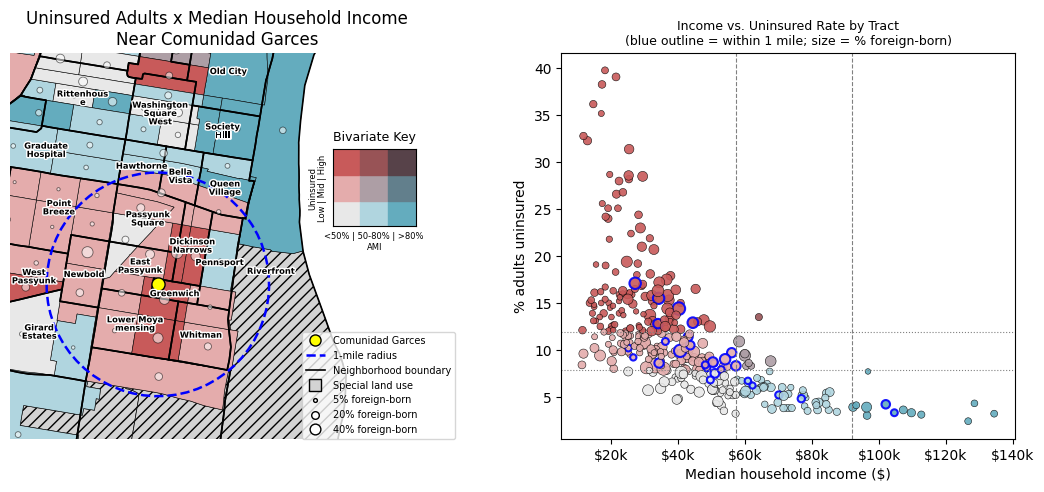

Tercile cutoffs: 33rd percentile = 7.8%, 66th percentile = 11.9%

Low (bottom third): n=124 tracts, range 2.4%–7.8%, mean 5.7%
Mid (middle third): n=123 tracts, range 7.9%–11.9%, mean 9.8%
High (top third): n=127 tracts, range 12.0%–39.8%, mean 17.4%

Interpretation: Tracts immediately around Comunidad Garces show a mix of mid-to-high
uninsured rates paired with below-80%-AMI incomes (darker teal/maroon cells), suggesting
the surrounding population has both elevated coverage gaps with lower income — the group
most likely to benefit from co-located free medical and dental resources. Tracts farther
from the buffer that show similarly high uninsured/low-income profiles are not left
entirely unserved: the Race St Clinic and mobile health service units, as well as other
pop-up Community Health Days, extend coverage into areas outside Comunidad Garces's
immediate footprint, so the map should be read as identifying priority areas for
Comunidad Garces specifically, not as the sole source of ca

In [15]:
## ===== Classification: terciles for uninsured, fixed HUD AMI bands for income =====
q33, q66 = biv2_valid['pct_uninsured'].quantile([0.33, 0.66])

def classify_uninsured(pct):
    if pct < q33:
        return 0        # lowest third
    elif pct < q66:
        return 1        # middle third
    else:
        return 2         # highest third

biv2_valid['uninsured_class'] = biv2_valid['pct_uninsured'].apply(classify_uninsured)

def classify_income(income):
    if income < 57350:
        return 0        # at/below Very Low Income (50% AMI)
    elif income < 91750:
        return 1        # Low Income band (50-80% AMI)
    else:
        return 2         # above Low Income threshold (80%+ AMI)

biv2_valid['income_class'] = biv2_valid['median_hh_income'].apply(classify_income)

bivariate_colors = {
    (0, 0): '#e8e8e8', (1, 0): '#b0d5df', (2, 0): '#64acbe',   # low uninsured row
    (0, 1): '#e4acac', (1, 1): '#ad9ea5', (2, 1): '#627f8c',   # mid uninsured row
    (0, 2): '#c85a5a', (1, 2): '#985356', (2, 2): '#574249',   # high uninsured row
}

biv2_valid['biv_color'] = biv2_valid.apply(
    lambda row: bivariate_colors[(row['income_class'], row['uninsured_class'])], axis=1
)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={'width_ratios': [1, 0.9]})

biv2_missing.plot(ax=ax, color='lightgray', edgecolor='black', linewidth=0.5, hatch='///')
biv2_valid.plot(ax=ax, color=biv2_valid['biv_color'], edgecolor='black', linewidth=0.4)

add_foreign_born_bubbles(ax, biv2_valid, scale=1.5)   # smaller scale: Map 1 is zoomed out

buffer_1mi.plot(ax=ax, color='none', edgecolor='blue', linewidth=1.8, linestyle='--', zorder=4)
ax.scatter(garces_lon, garces_lat, marker='o', color='yellow', s=90, zorder=5, edgecolor='black')

xlim = (garces_lon - 0.025, garces_lon + 0.045)
ylim = (garces_lat - 0.02, garces_lat + 0.03)

# neighborhood outlines + labels
texts = add_neighborhood_labels(ax, xlim, ylim, names=keep)

ax.set_xlim(*xlim)
ax.set_ylim(*ylim)

ax.set_title('Uninsured Adults x Median Household Income\nNear Comunidad Garces')
ax.axis('off')

point = Line2D([0], [0], label='Comunidad Garces', marker='o', markersize=8,
               markeredgecolor='black', markerfacecolor='yellow', linestyle='')
buffer_handle = Line2D([0], [0], label='1-mile radius', color='blue',
                       linewidth=1.8, linestyle='--')
neigh_handle = Line2D([0], [0], label='Neighborhood boundary', color='black', linewidth=1.2)
no_data = Line2D([0], [0], label='Special land use', marker='s', markersize=8,
                 markerfacecolor='lightgray', markeredgecolor='black', linestyle='')

ax.legend(handles=[point, buffer_handle, neigh_handle, no_data] + foreign_born_legend_handles(scale=1.5),
          loc='lower right', bbox_to_anchor=(1.075, 0), borderaxespad=0, fontsize=7)

legend_ax = ax.inset_axes([0.78, 0.55, 0.20, 0.20])
for income_c in range(3):
    for uninsured_c in range(3):
        legend_ax.add_patch(plt.Rectangle((income_c, uninsured_c), 1, 1,
                                           color=bivariate_colors[(income_c, uninsured_c)]))
legend_ax.set_xlim(0, 3)
legend_ax.set_ylim(0, 3)
legend_ax.set_xticks([])
legend_ax.set_yticks([])
legend_ax.set_xlabel('<50% | 50-80% | >80%\nAMI', fontsize=6)
legend_ax.set_ylabel('Uninsured\nLow | Mid | High', fontsize=6)
legend_ax.set_title('Bivariate Key', fontsize=9)

# ===== Scatterplot: income vs. uninsured, same colors as the map =====
in_buffer = biv2_valid.intersects(buffer_1mi.iloc[0])

ax2.scatter(biv2_valid['median_hh_income'], biv2_valid['pct_uninsured'],
            c=biv2_valid['biv_color'], s=15 + biv2_valid['pct_foreign_born'].fillna(0) * 1.5,
            edgecolor=np.where(in_buffer, 'blue', 'black'),
            linewidth=np.where(in_buffer, 1.5, 0.4), alpha=0.9)

# class boundaries
for x in (57350, 91750):
    ax2.axvline(x, color='gray', linestyle='--', linewidth=0.8)
for y in (q33, q66):
    ax2.axhline(y, color='gray', linestyle=':', linewidth=0.8)

ax2.set_xlabel('Median household income ($)')
ax2.set_ylabel('% adults uninsured')
ax2.set_title('Income vs. Uninsured Rate by Tract\n(blue outline = within 1 mile; size = % foreign-born)', fontsize=9)
ax2.xaxis.set_major_formatter(lambda x, _: f'${x/1000:.0f}k')

plt.tight_layout()

plt.show()

## ===== Report tercile boundaries and ranges for uninsured adults =====
print(f"Tercile cutoffs: 33rd percentile = {q33:.1f}%, 66th percentile = {q66:.1f}%\n")

for cls, label in [(0, 'Low (bottom third)'), (1, 'Mid (middle third)'), (2, 'High (top third)')]:
    subset = biv2_valid[biv2_valid['uninsured_class'] == cls]['pct_uninsured']
    print(f"{label}: n={len(subset)} tracts, "
          f"range {subset.min():.1f}%–{subset.max():.1f}%, "
          f"mean {subset.mean():.1f}%")

## ===== Report interpretation =====
print("""
Interpretation: Tracts immediately around Comunidad Garces show a mix of mid-to-high
uninsured rates paired with below-80%-AMI incomes (darker teal/maroon cells), suggesting
the surrounding population has both elevated coverage gaps with lower income — the group
most likely to benefit from co-located free medical and dental resources. Tracts farther
from the buffer that show similarly high uninsured/low-income profiles are not left
entirely unserved: the Race St Clinic and mobile health service units, as well as other
pop-up Community Health Days, extend coverage into areas outside Comunidad Garces's
immediate footprint, so the map should be read as identifying priority areas for
Comunidad Garces specifically, not as the sole source of care access across the city.
""")

print("""
Merge diagnostics summary (Map 1, final):

Step 1 (2015-vintage tracts x CDC PLACES uninsured): 376 matched, 8 left_only,
0 right_only. The CDC PLACES codebook (em5e-5hvn) documents these estimates as
joinable with the 2015 census tract boundary file; switching from the original
2020-vintage shapefile to a matching 2015-vintage shapefile resolved the prior
358/50/18 mismatch almost entirely. The remaining 8 left_only tracts reflect
standard small-population/CDC suppression, not a vintage or key error.

Step 2 (+ ACS median household income, 2011-2015 5-year estimate): 384 matched,
0 left_only, 0 right_only. Pulling income data from the ACS vintage matching
phT_2015 (rather than the 2018-2022/2020-vintage estimate used in Map 2)
fully resolved the earlier 21/45 mismatch -- a perfect merge across all 384
tracts.

Verdict: both merge steps are now fully explained and, on the income side,
fully resolved. The 8 remaining CDC gaps are documented, expected suppression,
not an error. This directly demonstrates the workflow requested: check the
codebook for tract vintage, obtain a matching shapefile, and merge -- applied
to two independently-sourced datasets (CDC PLACES and ACS), satisfying the
requirement of at least two merges across shapefiles from different sources.

Note: because Map 1 now uses the 2011-2015 ACS estimate for income (to match
CDC's tract vintage) while Map 2 uses the 2018-2022 ACS estimate (to match its
LEP variable's vintage), the two maps' income figures reflect different survey
periods, though both apply the same HUD AMI classification thresholds.
""")

****
## **Map 2: Bivariate map — Household LEP x Median Household Income**

**Limited English Proficiency (LEP)** - Linguistically-isolated households, i.e., Spanish-speaking households that are "Limited English speaking household" (no one 14+ speaks English "very well")
* LEP threshold — DOJ/HHS Title VI "Safe Harbor" provision
Federal guidance under Title VI (following Executive Order 13166) sets the recognized threshold at written translation being required for each eligible LEP language group that constitutes five percent or 1,000 people, whichever is less, of the population eligible to be served. In practice, for a tract-level map, this means: 5% household LEP rate is the recognized "significant population" trigger — below 5% is not officially recognized as requiring language access accommodation, at or above 5% is.
(U.S. Department of Health and Human Services)

**Income** — HUD Area Median Income (AMI) brackets
* For the Philadelphia-Camden-Wilmington, PA-NJ-DE-MD MSA, FY2024 HUD income limits for a 4-person household are: 30% LIMITS 34,400; VERY LOW INCOME (50%) 57,350; 60% LIMITS 68,820; LOW INCOME (80%) 91,750. The standard three-tier HUD system is extremely low-income (30% AMI), very low-income (50% AMI), and low-income (80% AMI).
(HUD)

Since median household income (not adjusted for household size) is what I'm pulling from ACS, the cleanest way to bucket tracts is against the 4-person benchmark, with a clear caveat that HUD's brackets are technically household-size-adjusted and mine is a simplification.

In [16]:
## **Map 2: Bivariate map — Household LEP x Median Household Income**

# ===== Merge diagnostics for Map 2 (LEP x income x foreign-born) =====

# Check for duplicate GEOIDs in each source table first
print("Duplicate GEOIDs check:")
print(f"  phT: {phT['GEOID'].duplicated().sum()} duplicates")
print(f"  acs_lep_hh: {acs_lep_hh['GEOID'].duplicated().sum()} duplicates")
print(f"  acs_income: {acs_income['GEOID'].duplicated().sum()} duplicates")
print(f"  acs_fb: {acs_fb['GEOID'].duplicated().sum()} duplicates\n")

# Step 1: tracts x LEP
check1 = phT.merge(acs_lep_hh[['GEOID', 'pct_lep_spanish_hh']], on='GEOID', how='outer', indicator=True)
print("Step 1 (tracts x LEP):")
print(check1['_merge'].value_counts(), "\n")

print("Left-only GEOIDs (Philly tracts with no LEP row — expected, becomes 'missing' hatch):")
print(f"  n = {(check1['_merge'] == 'left_only').sum()}\n")

print("Right-only GEOIDs (LEP rows that aren't Philly tracts — should be empty):")
print(check1[check1['_merge'] == 'right_only']['GEOID'].tolist(), "\n")

# Step 2: + income
check2 = check1.merge(acs_income[['GEOID', 'median_hh_income']], on='GEOID', how='outer', indicator='_merge2')
print("Step 2 (+ income):")
print(check2['_merge2'].value_counts(), "\n")

print("Right-only GEOIDs (income rows that aren't Philly tracts — should be empty):")
print(check2[check2['_merge2'] == 'right_only']['GEOID'].tolist(), "\n")

# Step 3: + foreign-born
check3 = check2.merge(acs_fb[['GEOID', 'pct_foreign_born']], on='GEOID', how='outer', indicator='_merge3')
print("Step 3 (+ foreign-born):")
print(check3['_merge3'].value_counts(), "\n")

print("Right-only GEOIDs (foreign-born rows that aren't Philly tracts — should be empty):")
print(check3[check3['_merge3'] == 'right_only']['GEOID'].tolist(), "\n")

# Row count sanity check
print(f"phT rows: {len(phT)}")
print(f"check3 rows: {len(check3)}")
assert len(check3) == len(phT) + (check3['_merge3'] == 'right_only').sum() + (check3['_merge2'] == 'right_only').sum(), \
    "Row count mismatch — investigate duplicates or fan-out"

print("\nMissingness cross-tab (LEP status x income status):")
print(pd.crosstab(
    check3['pct_lep_spanish_hh'].isna().map({True: 'LEP missing', False: 'LEP present'}),
    check3['median_hh_income'].isna().map({True: 'income missing', False: 'income present'})
))

# ===== Merge + simplify (single pass) =====
biv = phT.merge(acs_lep_hh[['GEOID', 'pct_lep_spanish_hh']], on='GEOID', how='left')
biv = biv.merge(acs_income[['GEOID', 'median_hh_income']], on='GEOID', how='left')
biv = biv.merge(acs_fb[['GEOID', 'pct_foreign_born']], on='GEOID', how='left')
biv = biv[['GEOID', 'geometry', 'pct_lep_spanish_hh', 'median_hh_income', 'pct_foreign_born']]

# ===== Now derive valid/missing from the trimmed frame =====
biv_4326 = biv.to_crs(epsg=4326)
biv_valid = biv_4326.dropna(subset=['pct_lep_spanish_hh', 'median_hh_income']).copy()
biv_missing = biv_4326[biv_4326['pct_lep_spanish_hh'].isna() | biv_4326['median_hh_income'].isna()]

Duplicate GEOIDs check:
  phT: 0 duplicates
  acs_lep_hh: 0 duplicates
  acs_income: 0 duplicates
  acs_fb: 0 duplicates

Step 1 (tracts x LEP):
_merge
both          408
left_only       0
right_only      0
Name: count, dtype: int64 

Left-only GEOIDs (Philly tracts with no LEP row — expected, becomes 'missing' hatch):
  n = 0

Right-only GEOIDs (LEP rows that aren't Philly tracts — should be empty):
[] 

Step 2 (+ income):
_merge2
both          408
left_only       0
right_only      0
Name: count, dtype: int64 

Right-only GEOIDs (income rows that aren't Philly tracts — should be empty):
[] 

Step 3 (+ foreign-born):
_merge3
both          408
left_only       0
right_only      0
Name: count, dtype: int64 

Right-only GEOIDs (foreign-born rows that aren't Philly tracts — should be empty):
[] 

phT rows: 408
check3 rows: 408

Missingness cross-tab (LEP status x income status):
median_hh_income    income missing  income present
pct_lep_spanish_hh                                
LEP missing 

In [17]:
# ===== Categorize missing tracts: Map 2 (LEP x income) =====

# acs_lep_hh doesn't carry a population column in your current pull_acs_table_from_github
# call, so we approximate "low population" using the LEP universe denominator itself
# (C16002_001E = total households used as the LEP base) — very low denominator households
# behave the same way as low population for suppression purposes.

missing_lep = biv_4326[biv_4326['pct_lep_spanish_hh'].isna()]

df_lep = missing_lep[['GEOID']].copy()
df_lep['tract_code'] = df_lep['GEOID'].str[5:]
df_lep['is_special_tract'] = df_lep['tract_code'].str.startswith(('98', '99'))
df_lep = df_lep.merge(acs_lep_hh[['GEOID', 'C16002_001E']], on='GEOID', how='left')
df_lep['low_household_base'] = df_lep['C16002_001E'] < 50  # tune threshold as needed

def bucket_lep(row):
    if row['is_special_tract']:
        return 'special/non-residential tract'
    elif pd.isna(row['C16002_001E']):
        return 'no ACS row at all — investigate (vintage/GEOID mismatch?)'
    elif row['low_household_base']:
        return 'low household base (likely suppressed/unreliable)'
    else:
        return 'unexplained — investigate'

df_lep['category'] = df_lep.apply(bucket_lep, axis=1)

print("Map 2 — missing 'pct_lep_spanish_hh' tract breakdown:")
print(df_lep['category'].value_counts(), "\n")
print(df_lep.sort_values('category'))

Map 2 — missing 'pct_lep_spanish_hh' tract breakdown:
category
special/non-residential tract                        19
low household base (likely suppressed/unreliable)     1
Name: count, dtype: int64 

          GEOID tract_code  is_special_tract  C16002_001E  low_household_base  \
13  42101036901     036901             False            0                True   
0   42101980003     980003              True            0                True   
17  42101989300     989300              True            0                True   
16  42101980901     980901              True            0                True   
15  42101980002     980002              True            0                True   
14  42101980001     980001              True            0                True   
12  42101989200     989200              True            0                True   
11  42101980702     980702              True            0                True   
10  42101980500     980500              True            0           

In [18]:
# --- Map 2 (2020 vintage) ---
chk = biv.merge(acs_fb[['GEOID', 'pct_foreign_born']], on='GEOID', how='outer', indicator=True)
print("Map 2 + foreign-born:\n", chk['_merge'].value_counts(), "\n")

biv = biv.merge(acs_fb[['GEOID', 'pct_foreign_born']], on='GEOID', how='left')
# ...then re-derive biv_4326 / biv_valid / biv_missing exactly as before

Map 2 + foreign-born:
 _merge
both          408
left_only       0
right_only      0
Name: count, dtype: int64 



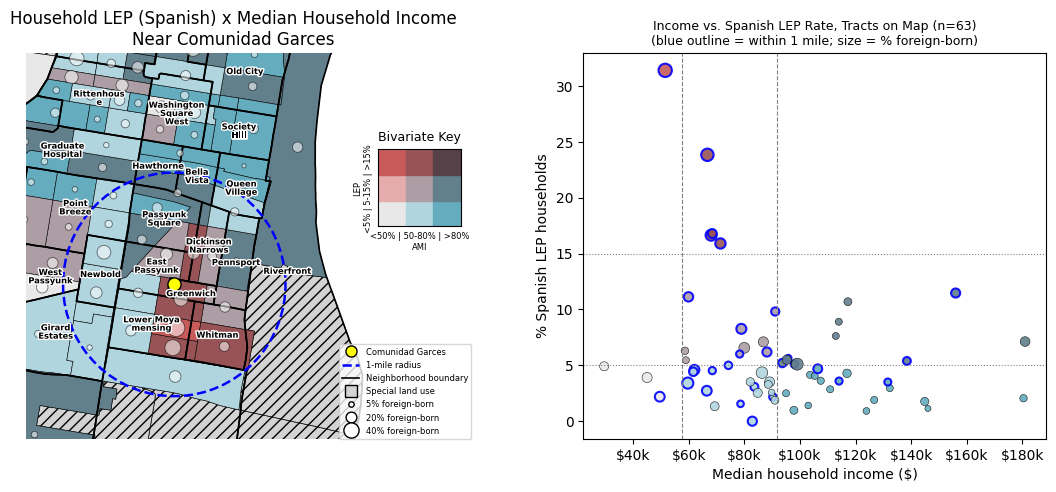


Interpretation: Several tracts within the 1-mile buffer exceed the 5% Title VI Safe Harbor
threshold for Spanish LEP households while also falling below 80% AMI, indicating that affordable
ESL, digital literacy, and GED classes, which promote upward mobility, would be beneficial
for a meaningful share of Comunidad Garces's low-income service area. High-LEP,
low-income tracts outside the buffer are partly addressed through online classes, which can
extend language and other support services to households beyond easy walking/transit distance
of the physical site.


Merge diagnostics summary:
  - 0 left_only, 0 right_only at the merge step -- every phT tract matched
    exactly one acs_lep_hh row. The merge itself is fully correct.
  - The 20 "missing" tracts appearing later are NaN values within a
    successful merge: 19 are special/non-residential tracts with 0 reported
    households, and 1 (GEOID 42101036901) was a divide-by-zero artifact in
    the pct_lep_spanish_hh calculation (0

In [19]:
## ===== Fixed-threshold bivariate classification (HUD AMI x Title VI LEP Safe Harbor) =====

def classify_lep(pct):
    if pct < 5:
        return 0        # below Title VI Safe Harbor threshold
    elif pct < 15:
        return 1        # meets/exceeds Safe Harbor threshold
    else:
        return 2         # substantially exceeds threshold (elevated need)

biv_valid['lep_class'] = biv_valid['pct_lep_spanish_hh'].apply(classify_lep)

def classify_income(income):
    if income < 57350:
        return 0        # at/below Very Low Income (50% AMI)
    elif income < 91750:
        return 1        # Low Income band (50-80% AMI)
    else:
        return 2         # above Low Income threshold (80%+ AMI)

biv_valid['income_class'] = biv_valid['median_hh_income'].apply(classify_income)

bivariate_colors = {
    (0, 0): '#e8e8e8', (1, 0): '#b0d5df', (2, 0): '#64acbe',   # low LEP row
    (0, 1): '#e4acac', (1, 1): '#ad9ea5', (2, 1): '#627f8c',   # mid LEP row
    (0, 2): '#c85a5a', (1, 2): '#985356', (2, 2): '#574249',   # high LEP row
}

biv_valid['biv_color'] = biv_valid.apply(
    lambda row: bivariate_colors[(row['income_class'], row['lep_class'])], axis=1
)

xlim = (garces_lon - 0.025, garces_lon + 0.045)
ylim = (garces_lat - 0.02, garces_lat + 0.03)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={'width_ratios': [1, 0.9]})

# 1. data layers
biv_missing.plot(ax=ax, color='lightgray', edgecolor='black', linewidth=0.5, hatch='///')
biv_valid.plot(ax=ax, color=biv_valid['biv_color'], edgecolor='black', linewidth=0.4)
add_foreign_born_bubbles(ax, biv_valid, scale=3)

# 2. buffer + site
buffer_1mi.plot(ax=ax, color='none', edgecolor='blue', linewidth=1.8, linestyle='--', zorder=4)
ax.scatter(garces_lon, garces_lat, marker='o', color='yellow', s=90, zorder=5, edgecolor='black')

# 3. neighborhood outlines + labels (ONE call only)
texts = add_neighborhood_labels(ax, xlim, ylim, names=keep)

#to check all labels: add_neighborhood_labels(ax, xlim, ylim)

# 4. limits
ax.set_xlim(*xlim)
ax.set_ylim(*ylim)

ax.set_title('Household LEP (Spanish) x Median Household Income\nNear Comunidad Garces')
ax.axis('off')

# 5. main legend
point = Line2D([0], [0], label='Comunidad Garces', marker='o', markersize=8,
               markeredgecolor='black', markerfacecolor='yellow', linestyle='')
buffer_handle = Line2D([0], [0], label='1-mile radius', color='blue',
                       linewidth=1.8, linestyle='--')
neigh_handle = Line2D([0], [0], label='Neighborhood boundary', color='black', linewidth=1.2)
no_data = Line2D([0], [0], label='Special land use', marker='s', markersize=8,
                 markerfacecolor='lightgray', markeredgecolor='black', linestyle='')
ax.legend(handles=[point, buffer_handle, neigh_handle, no_data] + foreign_born_legend_handles(scale=3),
          loc='lower right', bbox_to_anchor=(1.075, 0), borderaxespad=0, fontsize=6)

# 6. bivariate key
legend_ax = ax.inset_axes([0.85, 0.55, 0.20, 0.20])
for income_c in range(3):
    for lep_c in range(3):
        legend_ax.add_patch(plt.Rectangle((income_c, lep_c), 1, 1,
                                          color=bivariate_colors[(income_c, lep_c)]))
legend_ax.set_xlim(0, 3); legend_ax.set_ylim(0, 3)
legend_ax.set_xticks([]); legend_ax.set_yticks([])
legend_ax.set_xlabel('<50% | 50-80% | >80%\nAMI', fontsize=6)
legend_ax.set_ylabel('LEP\n<5% | 5-15% | >15%', fontsize=6)
legend_ax.set_title('Bivariate Key', fontsize=9)

view = biv_valid.cx[xlim[0]:xlim[1], ylim[0]:ylim[1]]     # tracts that appear in the zoomed map

add_scatter(ax2, view, 'pct_lep_spanish_hh', '% Spanish LEP households',
            hlines=(5, 15), title=f'Income vs. Spanish LEP Rate, Tracts on Map (n={len(view)})')

plt.show()

## ===== Report interpretation =====
print("""
Interpretation: Several tracts within the 1-mile buffer exceed the 5% Title VI Safe Harbor
threshold for Spanish LEP households while also falling below 80% AMI, indicating that affordable
ESL, digital literacy, and GED classes, which promote upward mobility, would be beneficial
for a meaningful share of Comunidad Garces's low-income service area. High-LEP,
low-income tracts outside the buffer are partly addressed through online classes, which can
extend language and other support services to households beyond easy walking/transit distance
of the physical site.
""")

print("""
Merge diagnostics summary:
  - 0 left_only, 0 right_only at the merge step -- every phT tract matched
    exactly one acs_lep_hh row. The merge itself is fully correct.
  - The 20 "missing" tracts appearing later are NaN values within a
    successful merge: 19 are special/non-residential tracts with 0 reported
    households, and 1 (GEOID 42101036901) was a divide-by-zero artifact in
    the pct_lep_spanish_hh calculation (0 LEP households / 0 total
    households), now handled explicitly rather than silently producing NaN.
""")

In [33]:
# ===== Interactive map (folium): Lower Moyamensing vs. Passyunk Square =====
# Run after Map 2. Needs: biv_valid (with 'biv_color'), neigh, garces_lat, garces_lon, bivariate_colors.
# folium is preinstalled in Colab; otherwise run:  !pip install folium -q

NAMES = ['Lower Moyamensing', 'Passyunk Square']
sel = neigh[neigh['MAPNAME'].isin(NAMES)]

# round the numbers shown in the hover tooltip
tr = biv_valid[['GEOID', 'median_hh_income', 'pct_lep_spanish_hh', 'pct_foreign_born',
                'biv_color', 'geometry']].copy()
tr['median_hh_income'] = tr['median_hh_income'].round(0)
tr['pct_lep_spanish_hh'] = tr['pct_lep_spanish_hh'].round(1)
tr['pct_foreign_born'] = tr['pct_foreign_born'].round(1)

m = folium.Map(location=[garces_lat, garces_lon], zoom_start=15, tiles=None)

# basemap layers (toggle in the layer control): aerial is the default
folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr='Tiles &copy; Esri, Maxar, Earthstar Geographics', name='Aerial imagery', show=True).add_to(m)
folium.TileLayer('OpenStreetMap', name='Street map', show=False).add_to(m)

# Map 2 colors, semi-transparent, with hover tooltips
folium.GeoJson(
    json.loads(tr.to_json()),            # to_json turns NaN into null, which browsers accept
    name='Tracts (Spanish LEP x income)',
    style_function=lambda f: {'fillColor': f['properties']['biv_color'], 'fillOpacity': 0.55,
                              'color': 'black', 'weight': 0.8},
    tooltip=folium.GeoJsonTooltip(
        fields=['median_hh_income', 'pct_lep_spanish_hh', 'pct_foreign_born'],
        aliases=['Median income ($)', '% Spanish LEP hh', '% foreign-born'])).add_to(m)

# neighborhood outlines (no fill, so the tract tooltips still work)
folium.GeoJson(
    json.loads(sel[['MAPNAME', 'geometry']].to_json()),
    name='Neighborhoods',
    style_function=lambda f: {'color': 'white', 'weight': 4, 'fill': False},
    tooltip=folium.GeoJsonTooltip(fields=['MAPNAME'], aliases=['Neighborhood'], sticky=False)).add_to(m)

# Garces and the 1-mile radius
folium.Circle([garces_lat, garces_lon], radius=1609.34, color='blue', weight=2,
              dash_array='8', fill=False, name='1-mile radius').add_to(m)
folium.CircleMarker([garces_lat, garces_lon], radius=8, color='black', weight=1.5,
                    fill=True, fill_color='yellow', fill_opacity=1,
                    tooltip='Comunidad Garces').add_to(m)

# zoom to the two neighborhoods
minx, miny, maxx, maxy = sel.total_bounds
m.fit_bounds([[miny, minx], [maxy, maxx]])

# small bivariate key (income across, LEP up; same layout as the Map 2 key)
rows = ''.join(
    '<div>' + ''.join(
        f'<span style="display:inline-block;width:18px;height:18px;background:{bivariate_colors[(i, v)]}"></span>'
        for i in range(3)) + '</div>'
    for v in (2, 1, 0))
key_html = ('<div style="position:fixed;bottom:25px;left:25px;z-index:9999;background:white;'
            'padding:6px 8px;border:1px solid gray;font-size:11px;line-height:1.2">'
            '<b>Spanish LEP x income</b><br>' + rows +
            '<span>income: low &rarr; high<br>LEP: low (bottom) &rarr; high (top)</span></div>')
m.get_root().html.add_child(folium.Element(key_html))

folium.LayerControl(collapsed=False).add_to(m)
m.save('neighborhood_map.html')          # shareable file; open in any browser
m                                        # displays inline in the notebook


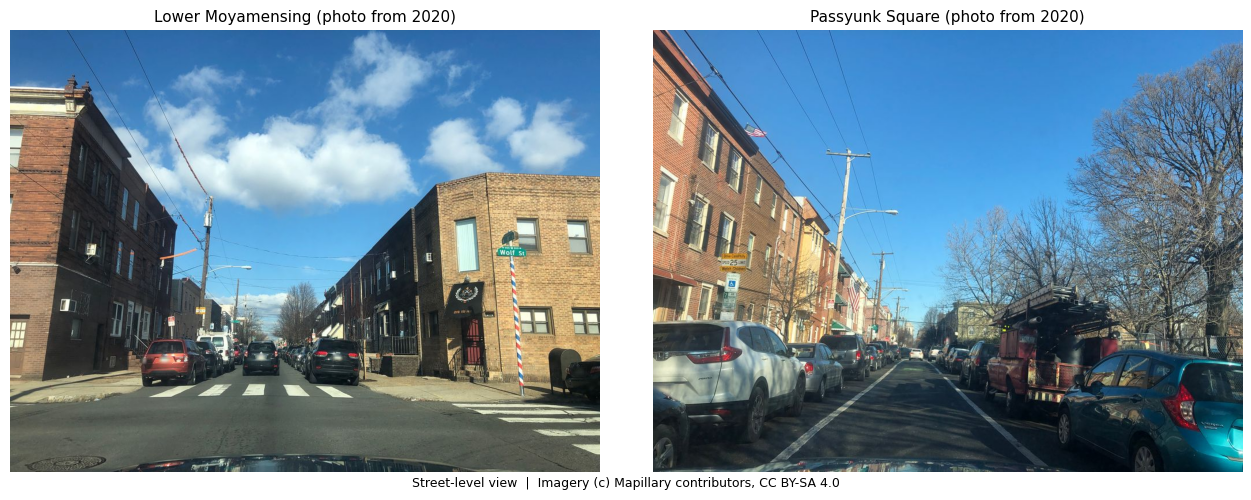

In [39]:
# ===== Street-level photos: Lower Moyamensing vs. Passyunk Square (Mapillary) =====
# Mapillary = crowd-sourced street-level imagery, free API, CC BY-SA 4.0 (credit it in your caption).
# Token (free): mapillary.com/developer -> register an application -> copy the client token.
# Needs: neigh (neighborhood polygons). No Google key or billing required.

import io
import requests
import pandas as pd
from PIL import Image

MAPILLARY_TOKEN = "MLY|39408693612109114|44e3d9cee40cf3e7bd0132cebaa2f241"
NAMES = ['Lower Moyamensing', 'Passyunk Square']
RADIUS_DEG = 0.0015            # ~150 m search box around each spot; widen if nothing is found

# Better than the neighborhood center: pick a street you want to show. Right-click the spot in
# Google Maps, click the coordinates to copy them, and paste as (lat, lon). None = use the neighborhood center.
SPOTS = {'Lower Moyamensing': (39.919563, -75.162030), 'Passyunk Square': (39.931644, -75.164330)}

def get_spot(name):
    if SPOTS.get(name):
        return SPOTS[name]
    p = neigh[neigh['MAPNAME'] == name].dissolve().geometry.iloc[0].representative_point()
    return p.y, p.x

def mapillary_photo(lat, lon, radius=RADIUS_DEG):
    """Newest non-panoramic photo within the search box; returns (PIL image, year) or (None, None)."""
    bbox = f"{lon - radius},{lat - radius},{lon + radius},{lat + radius}"
    r = requests.get("https://graph.mapillary.com/images", params={
        'access_token': MAPILLARY_TOKEN, 'bbox': bbox, 'limit': 100,
        'fields': 'id,captured_at,is_pano,thumb_1024_url'}, timeout=60)
    r.raise_for_status()
    data = [d for d in r.json().get('data', []) if not d.get('is_pano') and d.get('thumb_1024_url')]
    if not data:
        return None, None
    best = max(data, key=lambda d: d['captured_at'])              # most recent
    img = Image.open(io.BytesIO(requests.get(best['thumb_1024_url'], timeout=60).content))
    return img, pd.to_datetime(best['captured_at'], unit='ms').year

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name in zip(axes, NAMES):
    lat, lon = get_spot(name)
    img, year = mapillary_photo(lat, lon)
    if img is None:
        ax.text(0.5, 0.5, 'No Mapillary photo found here.\nWiden RADIUS_DEG or set SPOTS.',
                ha='center', va='center')
        ax.set_title(name)
    else:
        ax.imshow(img)
        ax.set_title(f'{name} (photo from {year})', fontsize=11)
    ax.axis('off')

fig.suptitle('Street-level view  |  Imagery (c) Mapillary contributors, CC BY-SA 4.0', fontsize=9, y=0.02)
plt.tight_layout()
plt.show()

# ---- Using your own photos instead (or to replace one that Mapillary missed) ----
# img = Image.open('lower_moyamensing.jpg')   # upload the file to the notebook first
# ax.imshow(img); ax.axis('off')

# ---- For the folium map: a clickable Google Street View link (no key needed; opens in a new tab) ----
# for name in NAMES:
#     lat, lon = get_spot(name)
#     url = f"https://www.google.com/maps/@?api=1&map_action=pano&viewpoint={lat},{lon}"
#     folium.Marker([lat, lon], tooltip=f"{name}: click for Street View",
#                   popup=folium.Popup(f'<a href="{url}" target="_blank">Open Street View</a>', max_width=200)).add_to(m)

****
## **Map 3: Bivariate map — Digital Access x Median Household Income**

acs_dig: 0 duplicate GEOIDs

Map 3 (tracts x no-computer):
_merge
both          408
left_only       0
right_only      0
Name: count, dtype: int64 

Right-only GEOIDs (should be empty): []

Map 3 (tracts x foreign-born):
_merge
both          408
left_only       0
right_only      0
Name: count, dtype: int64 



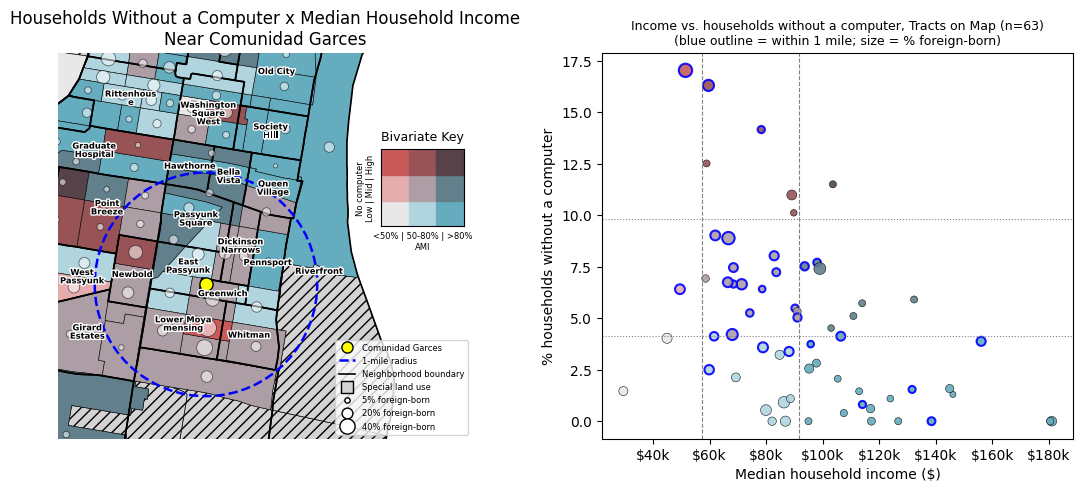

Tercile cutoffs for pct_no_computer: 33rd = 4.1%, 66th = 9.8%
  Low: n=127, range 0.0%-4.1%, mean 2.0%
  Mid: n=126, range 4.2%-9.8%, mean 6.7%
  High: n=130, range 10.0%-37.5%, mean 15.5%


In [28]:
## **Map 3: Bivariate map — No Home Computer x Median Household Income**

# ===== Merge diagnostics for Map 3 =====
print(f"acs_dig: {acs_dig['GEOID'].duplicated().sum()} duplicate GEOIDs\n")

base = biv.drop(columns=['pct_foreign_born'], errors='ignore')

check = base.merge(acs_dig[['GEOID', 'pct_no_computer']], on='GEOID', how='outer', indicator=True)
print("Map 3 (tracts x no-computer):")
print(check['_merge'].value_counts(), "\n")
print("Right-only GEOIDs (should be empty):", check[check['_merge'] == 'right_only']['GEOID'].tolist())

check_fb = base.merge(acs_fb[['GEOID', 'pct_foreign_born']], on='GEOID', how='outer', indicator=True)
print("\nMap 3 (tracts x foreign-born):")
print(check_fb['_merge'].value_counts(), "\n")

# ===== Merge + simplify =====
biv3 = base.merge(acs_dig[['GEOID', 'pct_no_computer']], on='GEOID', how='left')
biv3 = biv3.merge(acs_fb[['GEOID', 'pct_foreign_born']], on='GEOID', how='left')
biv3 = biv3[['GEOID', 'geometry', 'pct_no_computer', 'median_hh_income', 'pct_foreign_born']]

# ===== Map =====
biv3_valid, biv3_missing = plot_tercile_bivariate(
    biv3, 'pct_no_computer',
    'Households Without a Computer x Median Household Income\nNear Comunidad Garces',
    'No computer\nLow | Mid | High',
    '% households without a computer')

****
## **Map 4: Bivariate map — GED x Median Household Income**

acs_ged: 0 duplicate GEOIDs

Map 4 (tracts x no-HS-diploma):
_merge
both          408
left_only       0
right_only      0
Name: count, dtype: int64 

Right-only GEOIDs (should be empty): []

Map 4 (tracts x foreign-born):
_merge
both          408
left_only       0
right_only      0
Name: count, dtype: int64 



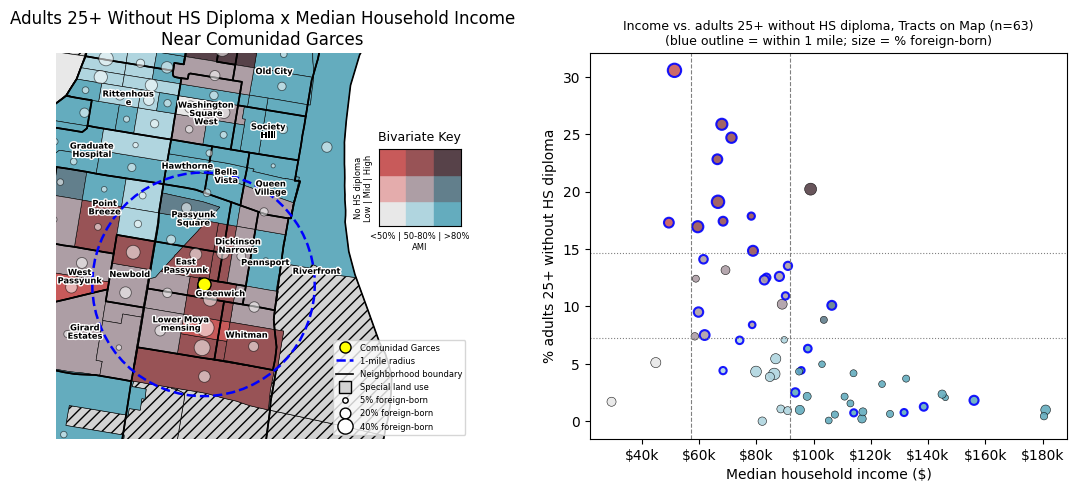

Tercile cutoffs for pct_no_hs: 33rd = 7.3%, 66th = 14.7%
  Low: n=127, range 0.0%-7.3%, mean 3.5%
  Mid: n=126, range 7.3%-14.7%, mean 10.7%
  High: n=130, range 14.7%-49.5%, mean 23.6%


In [29]:
## **Map 4: Bivariate map — Adults Without HS Diploma x Median Household Income**

# ===== Merge diagnostics for Map 4 =====
print(f"acs_ged: {acs_ged['GEOID'].duplicated().sum()} duplicate GEOIDs\n")

base = biv.drop(columns=['pct_foreign_born'], errors='ignore')

check = base.merge(acs_ged[['GEOID', 'pct_no_hs']], on='GEOID', how='outer', indicator=True)
print("Map 4 (tracts x no-HS-diploma):")
print(check['_merge'].value_counts(), "\n")
print("Right-only GEOIDs (should be empty):", check[check['_merge'] == 'right_only']['GEOID'].tolist())

check_fb = base.merge(acs_fb[['GEOID', 'pct_foreign_born']], on='GEOID', how='outer', indicator=True)
print("\nMap 4 (tracts x foreign-born):")
print(check_fb['_merge'].value_counts(), "\n")

# ===== Merge + simplify =====
biv4 = base.merge(acs_ged[['GEOID', 'pct_no_hs']], on='GEOID', how='left')
biv4 = biv4.merge(acs_fb[['GEOID', 'pct_foreign_born']], on='GEOID', how='left')
biv4 = biv4[['GEOID', 'geometry', 'pct_no_hs', 'median_hh_income', 'pct_foreign_born']]

# ===== Map =====
biv4_valid, biv4_missing = plot_tercile_bivariate(
    biv4, 'pct_no_hs',
    'Adults 25+ Without HS Diploma x Median Household Income\nNear Comunidad Garces',
    'No HS diploma\nLow | Mid | High',
    '% adults 25+ without HS diploma')

##Analyses for Interpretations

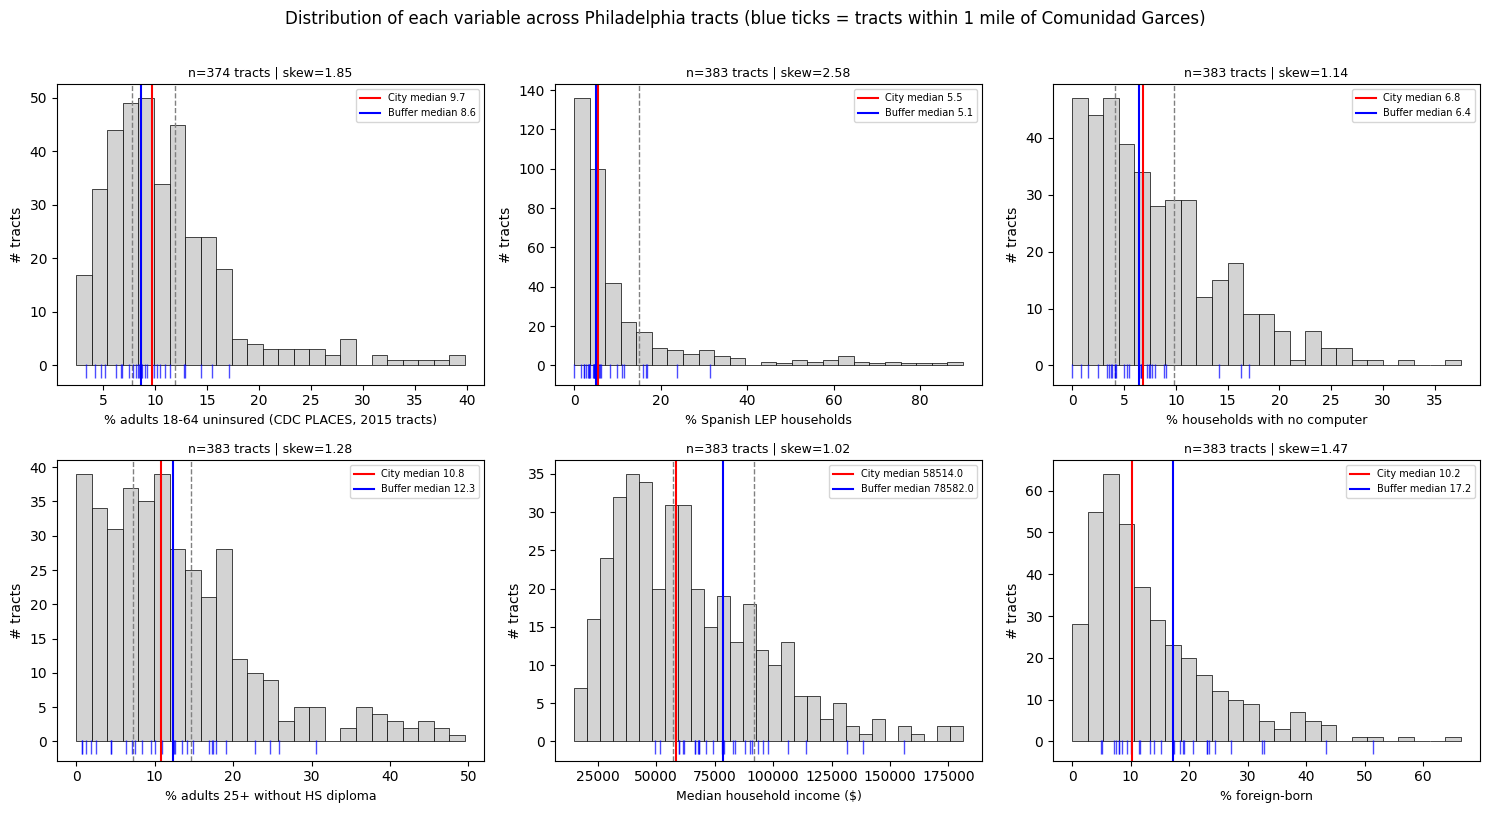

All six variables are right-skewed (skew of 1.0 to 2.6): most tracts 
cluster at low values, with a long tail of a few very high-need tracts. Spanish 
LEP is the most extreme (skew 2.58, with rates above 80% in a handful of tracts), 
so need is concentrated in a small number of tracts, not spread evenly, and 
medians describe the typical tract better than means.


In [22]:
# ===== CELL 1: Histograms of the main variables =====
# Run after Maps 1-4 so biv_valid, biv2_valid, biv3_valid, biv4_valid exist.
# Gray bars = all Philly tracts. Blue ticks along the bottom = tracts inside the 1-mile buffer.
# Dashed lines = the cutoffs used on the maps.

buf = buffer_1mi.iloc[0]

# (frame, column, x-label, cutoffs, cutoff-style, bins)
specs = [
    (biv2_valid, 'pct_uninsured',      '% adults 18-64 uninsured (CDC PLACES, 2015 tracts)', 'terciles', 25),
    (biv_valid,  'pct_lep_spanish_hh', '% Spanish LEP households',                           [5, 15],    25),
    (biv3_valid, 'pct_no_computer',    '% households with no computer',                      'terciles', 25),
    (biv4_valid, 'pct_no_hs',          '% adults 25+ without HS diploma',                    'terciles', 25),
    (biv_valid,  'median_hh_income',   'Median household income ($)',                        [57350, 91750], 30),
    (biv_valid,  'pct_foreign_born',   '% foreign-born',                                     None,       25),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (df, col, xlabel, cuts, bins) in zip(axes.ravel(), specs):
    vals = df[col].dropna()
    ax.hist(vals, bins=bins, color='lightgray', edgecolor='black', linewidth=0.5)

    if cuts == 'terciles':
        cuts = list(vals.quantile([0.33, 0.66]))
    for c in (cuts or []):
        ax.axvline(c, color='gray', linestyle='--', linewidth=1)

    # tracts inside the 1-mile buffer, drawn as ticks under the bars
    in_buf = df[df.intersects(buf)][col].dropna()
    ax.plot(in_buf, np.full(len(in_buf), -0.02 * ax.get_ylim()[1]), '|',
            color='blue', markersize=10, alpha=0.7, clip_on=False)

    ax.axvline(vals.median(), color='red', linewidth=1.5, label=f'City median {vals.median():.1f}')
    if len(in_buf):
        ax.axvline(in_buf.median(), color='blue', linewidth=1.5,
                   label=f'Buffer median {in_buf.median():.1f}')

    ax.set_xlabel(xlabel, fontsize=9)
    ax.set_ylabel('# tracts')
    ax.set_title(f'n={len(vals)} tracts | skew={vals.skew():.2f}', fontsize=9)
    ax.legend(fontsize=7)

fig.suptitle('Distribution of each variable across Philadelphia tracts '
             '(blue ticks = tracts within 1 mile of Comunidad Garces)', y=1.01)
plt.tight_layout()
plt.show()

print ("""All six variables are right-skewed (skew of 1.0 to 2.6): most tracts
cluster at low values, with a long tail of a few very high-need tracts. Spanish
LEP is the most extreme (skew 2.58, with rates above 80% in a handful of tracts),
so need is concentrated in a small number of tracts, not spread evenly, and
medians describe the typical tract better than means.""")

In [23]:
# ===== CELL 2: Buffer vs. citywide summary (use these numbers in your interpretation) =====
def summarize(df, col, label, rule):
    """rule(series) -> boolean mask of 'high need' tracts, using citywide cutoffs."""
    in_buf = df.intersects(buf)
    flag = rule(df[col])
    return {
        'Variable': label,
        'Tracts in buffer': int(in_buf.sum()),
        'City median': round(df[col].median(), 1),
        'Buffer median': round(df.loc[in_buf, col].median(), 1),
        '% city tracts flagged': round(100 * flag.mean(), 0),
        '% buffer tracts flagged': round(100 * flag[in_buf].mean(), 0),
    }

top_tercile = lambda s: s >= s.quantile(0.66)

rows = [
    summarize(biv2_valid, 'pct_uninsured',      'Uninsured (top tercile)',        top_tercile),
    summarize(biv_valid,  'pct_lep_spanish_hh', 'Spanish LEP >= 5% (Safe Harbor)', lambda s: s >= 5),
    summarize(biv_valid,  'pct_lep_spanish_hh', 'Spanish LEP >= 15%',              lambda s: s >= 15),
    summarize(biv3_valid, 'pct_no_computer',    'No computer (top tercile)',      top_tercile),
    summarize(biv4_valid, 'pct_no_hs',          'No HS diploma (top tercile)',    top_tercile),
    summarize(biv_valid,  'median_hh_income',   'Income < 80% AMI ($91,750)',
              lambda s: s < 91750),
    summarize(biv_valid,  'pct_foreign_born',   'Foreign-born (top tercile)',     top_tercile),
]
summary = pd.DataFrame(rows).set_index('Variable')
print(summary.to_string())

                                 Tracts in buffer  City median  Buffer median  % city tracts flagged  % buffer tracts flagged
Variable                                                                                                                     
Uninsured (top tercile)                        28          9.7            8.6                   34.0                     18.0
Spanish LEP >= 5% (Safe Harbor)                29          5.5            5.1                   54.0                     52.0
Spanish LEP >= 15%                             29          5.5            5.1                   21.0                     17.0
No computer (top tercile)                      29          6.8            6.4                   34.0                     10.0
No HS diploma (top tercile)                    29         10.8           12.3                   34.0                     34.0
Income < 80% AMI ($91,750)                     29      58514.0        78582.0                   82.0                  

In [24]:
# ===== CELL 3: The "double burden" count - how many buffer tracts are high-need AND low-income? =====
# (Red / maroon cells on the maps: low income x high need)
def double_burden(df, col, need_rule):
    in_buf = df.intersects(buf)
    hit = need_rule(df[col]) & (df['median_hh_income'] < 91750)
    return int(hit[in_buf].sum()), int(in_buf.sum()), int(hit.sum()), len(df)

for name, df, col, rule in [
    ('Uninsured',    biv2_valid, 'pct_uninsured',      top_tercile),
    ('Spanish LEP',  biv_valid,  'pct_lep_spanish_hh', lambda s: s >= 5),
    ('No computer',  biv3_valid, 'pct_no_computer',    top_tercile),
    ('No HS diploma', biv4_valid, 'pct_no_hs',         top_tercile),
]:
    b, nb, c, nc = double_burden(df, col, rule)
    print(f"{name:14s} buffer: {b}/{nb} tracts low-income + high-need | citywide: {c}/{nc}")

Uninsured      buffer: 5/28 tracts low-income + high-need | citywide: 127/374
Spanish LEP    buffer: 10/29 tracts low-income + high-need | citywide: 176/383
No computer    buffer: 3/29 tracts low-income + high-need | citywide: 127/383
No HS diploma  buffer: 10/29 tracts low-income + high-need | citywide: 128/383


In [25]:
for df, col in [(biv2_valid, 'pct_uninsured'), (biv_valid, 'pct_lep_spanish_hh'),
                (biv3_valid, 'pct_no_computer'), (biv4_valid, 'pct_no_hs')]:
    hi = df['pct_foreign_born'] >= df['pct_foreign_born'].quantile(0.66)
    print(f"{col}: high-immigrant tracts {df.loc[hi, col].median():.1f} vs other tracts {df.loc[~hi, col].median():.1f}")

pct_uninsured: high-immigrant tracts 10.0 vs other tracts 9.7
pct_lep_spanish_hh: high-immigrant tracts 8.2 vs other tracts 4.5
pct_no_computer: high-immigrant tracts 6.5 vs other tracts 7.2
pct_no_hs: high-immigrant tracts 12.7 vs other tracts 9.4


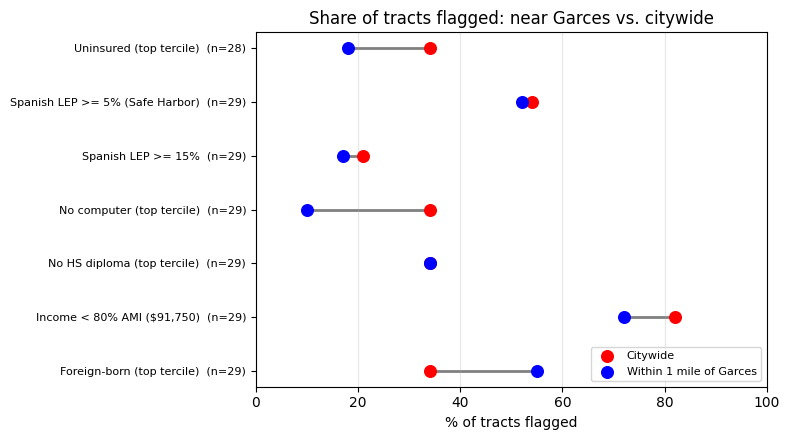

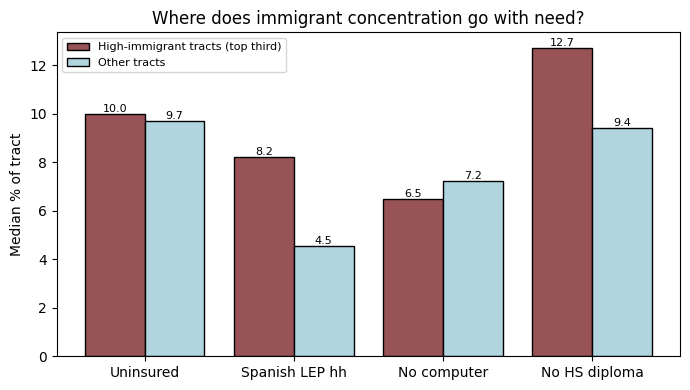

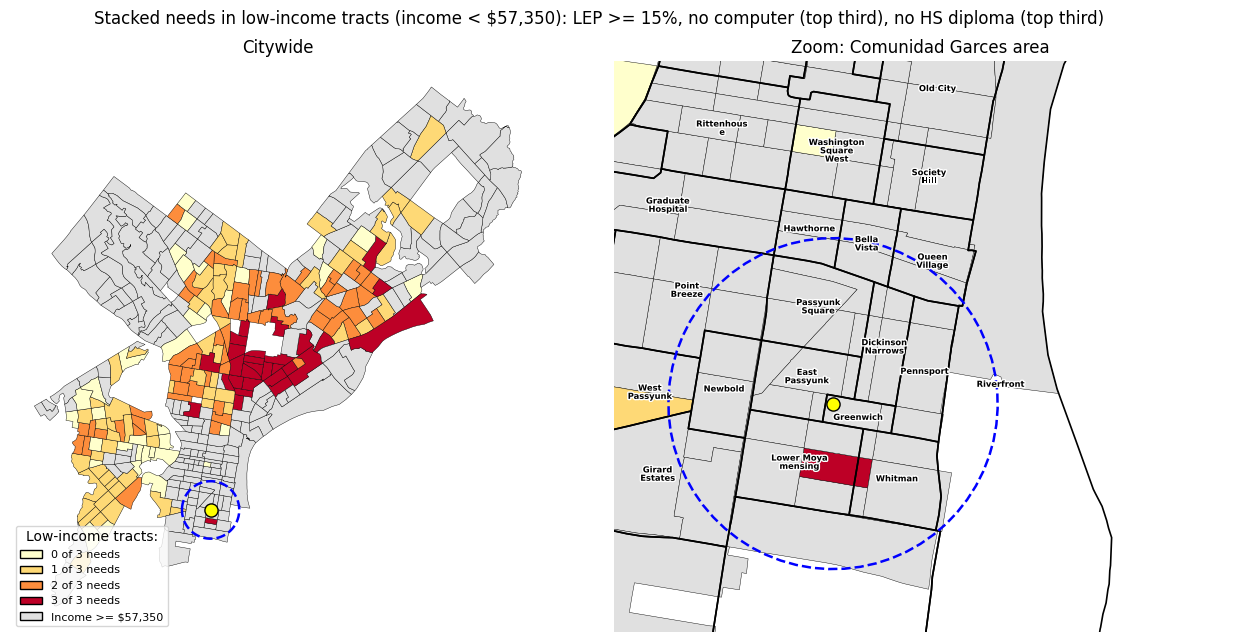

Low-income tracts: buffer 2/29, citywide 184/383
  0 needs: buffer 0, citywide 35
  1 needs: buffer 1, citywide 61
  2 needs: buffer 0, citywide 58
  3 needs: buffer 1, citywide 30
2+ needs: buffer 1/29 tracts, citywide 88/383 tracts


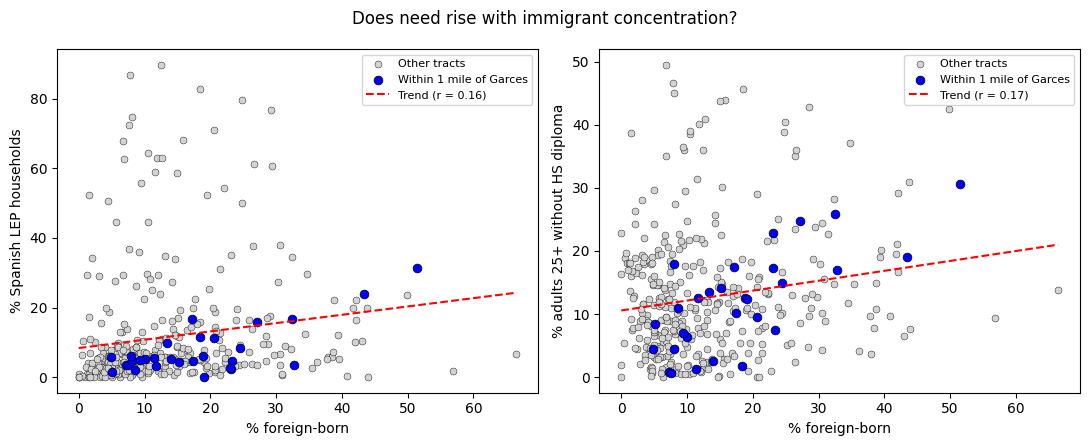

In [26]:
# Run after Cells 1-3 (needs: summary, buf, biv_valid, biv2_valid, biv3_valid, biv4_valid,
# garces_lon, garces_lat, buffer_1mi, add_neighborhood_labels, keep)
from matplotlib.patches import Patch

# ===== VISUAL 1: Buffer vs. citywide dumbbell =====
s = summary.iloc[::-1]
y = np.arange(len(s))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hlines(y, s['% city tracts flagged'], s['% buffer tracts flagged'], color='gray', linewidth=2, zorder=1)
ax.scatter(s['% city tracts flagged'], y, color='red', s=70, label='Citywide', zorder=3)
ax.scatter(s['% buffer tracts flagged'], y, color='blue', s=70, label='Within 1 mile of Garces', zorder=3)
ax.set_yticks(y)
ax.set_yticklabels([f"{name}  (n={n})" for name, n in zip(s.index, s['Tracts in buffer'])], fontsize=8)
ax.set_xlabel('% of tracts flagged')
ax.set_title('Share of tracts flagged: near Garces vs. citywide')
ax.set_xlim(0, 100)
ax.grid(axis='x', alpha=0.3)
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()


# ===== VISUAL 2: Need in high-immigrant vs. other tracts =====
pairs = [(biv2_valid, 'pct_uninsured', 'Uninsured'),
         (biv_valid, 'pct_lep_spanish_hh', 'Spanish LEP hh'),
         (biv3_valid, 'pct_no_computer', 'No computer'),
         (biv4_valid, 'pct_no_hs', 'No HS diploma')]
hi_vals, lo_vals, labels = [], [], []
for df, col, lab in pairs:
    hi = df['pct_foreign_born'] >= df['pct_foreign_born'].quantile(0.66)
    hi_vals.append(df.loc[hi, col].median())
    lo_vals.append(df.loc[~hi, col].median())
    labels.append(lab)

x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(7, 4))
b1 = ax.bar(x - 0.2, hi_vals, 0.4, color='#985356', edgecolor='black', label='High-immigrant tracts (top third)')
b2 = ax.bar(x + 0.2, lo_vals, 0.4, color='#b0d5df', edgecolor='black', label='Other tracts')
ax.bar_label(b1, fmt='%.1f', fontsize=8)
ax.bar_label(b2, fmt='%.1f', fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('Median % of tract')
ax.set_title('Where does immigrant concentration go with need?')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


# ===== VISUAL 3: Need-count map (low-income tracts, 2020 geometry) =====
# Adjust these thresholds if you want a different definition of "high need"
INCOME_CUT = 57350    # 50% AMI; use 91750 for the broader 80% AMI band
LEP_CUT = 15          # % Spanish LEP households

m = (biv_valid[['GEOID', 'geometry', 'pct_lep_spanish_hh', 'median_hh_income', 'pct_foreign_born']]
     .merge(biv3_valid[['GEOID', 'pct_no_computer']], on='GEOID', how='left')
     .merge(biv4_valid[['GEOID', 'pct_no_hs']], on='GEOID', how='left'))

m['f_lep'] = m['pct_lep_spanish_hh'] >= LEP_CUT
m['f_comp'] = m['pct_no_computer'] >= m['pct_no_computer'].quantile(0.66)
m['f_hs'] = m['pct_no_hs'] >= m['pct_no_hs'].quantile(0.66)
m['need_count'] = m[['f_lep', 'f_comp', 'f_hs']].sum(axis=1)
m['low_inc'] = m['median_hh_income'] < INCOME_CUT

palette = {0: '#ffffcc', 1: '#fed976', 2: '#fd8d3c', 3: '#bd0026'}
m['map_color'] = np.where(m['low_inc'], m['need_count'].map(palette), '#e0e0e0')

xlim = (garces_lon - 0.025, garces_lon + 0.045)
ylim = (garces_lat - 0.02, garces_lat + 0.03)

fig, (axA, axB) = plt.subplots(1, 2, figsize=(13, 6.5))
for ax_, zoom in [(axA, False), (axB, True)]:
    m.plot(ax=ax_, color=m['map_color'], edgecolor='black', linewidth=0.3)
    buffer_1mi.plot(ax=ax_, color='none', edgecolor='blue', linewidth=1.8, linestyle='--', zorder=4)
    ax_.scatter(garces_lon, garces_lat, color='yellow', edgecolor='black', s=90, zorder=5)
    if zoom:
        add_neighborhood_labels(ax_, xlim, ylim, names=keep)
        ax_.set_xlim(*xlim); ax_.set_ylim(*ylim)
        ax_.set_title('Zoom: Comunidad Garces area')
    else:
        ax_.set_title('Citywide')
    ax_.axis('off')

handles = [Patch(facecolor=palette[k], edgecolor='black',
                 label=f'{k} of 3 needs') for k in range(4)]
handles.append(Patch(facecolor='#e0e0e0', edgecolor='black', label=f'Income >= ${INCOME_CUT:,}'))
axA.legend(handles=handles, title='Low-income tracts:', loc='lower left', fontsize=8)
fig.suptitle(f'Stacked needs in low-income tracts (income < ${INCOME_CUT:,}): '
             f'LEP >= {LEP_CUT}%, no computer (top third), no HS diploma (top third)')
plt.tight_layout()
plt.show()

in_b = m.intersects(buf)
li = m['low_inc']
print(f"Low-income tracts: buffer {int((li & in_b).sum())}/{int(in_b.sum())}, citywide {int(li.sum())}/{len(m)}")
for k in range(4):
    kb = int(((m['need_count'] == k) & li & in_b).sum())
    kc = int(((m['need_count'] == k) & li).sum())
    print(f"  {k} needs: buffer {kb}, citywide {kc}")
print(f"2+ needs: buffer {int(((m['need_count'] >= 2) & li & in_b).sum())}/{int(in_b.sum())} tracts, "
      f"citywide {int(((m['need_count'] >= 2) & li).sum())}/{len(m)} tracts")


# ===== VISUAL 4: Immigrant share vs. LEP and no-diploma =====
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax_, col, lab in [(axes[0], 'pct_lep_spanish_hh', '% Spanish LEP households'),
                      (axes[1], 'pct_no_hs', '% adults 25+ without HS diploma')]:
    d = m.dropna(subset=['pct_foreign_born', col])
    inb = d.intersects(buf)
    ax_.scatter(d.loc[~inb, 'pct_foreign_born'], d.loc[~inb, col], color='lightgray',
                edgecolor='black', linewidth=0.3, s=25, label='Other tracts')
    ax_.scatter(d.loc[inb, 'pct_foreign_born'], d.loc[inb, col], color='blue',
                edgecolor='black', linewidth=0.5, s=40, label='Within 1 mile of Garces')
    slope, intercept = np.polyfit(d['pct_foreign_born'], d[col], 1)
    xs = np.linspace(d['pct_foreign_born'].min(), d['pct_foreign_born'].max(), 50)
    r = np.corrcoef(d['pct_foreign_born'], d[col])[0, 1]
    ax_.plot(xs, slope * xs + intercept, color='red', linestyle='--', label=f'Trend (r = {r:.2f})')
    ax_.set_xlabel('% foreign-born')
    ax_.set_ylabel(lab)
    ax_.legend(fontsize=8)
fig.suptitle('Does need rise with immigrant concentration?')
plt.tight_layout()
plt.show()

Uninsured adults: Only 5 of 28 tracts within a mile of Comunidad Garces (18%) are both low-income and in the highest third for uninsured adults, about half the citywide share (34%). Each of those 5 tracts is low-income. The highest uninsured rates are farther away, which is where the Race St Clinic and mobile health units extend care.

LEP: Ten of 29 buffer tracts (34%) are both low-income and above the 5% Safe Harbor threshold for Spanish LEP households. That is below the citywide share (46%) but still a third of the service area, enough to justify ESL and language-access services. The tracts with the highest LEP rates are mostly outside the buffer, so online classes help reach them.

Computers: Only 3 of 29 buffer tracts (10%) are low-income and high in no-computer households, versus 33% citywide. Digital literacy need near the site is concentrated in a few tracts, so these classes may serve a narrower group than the other services.

HS diploma: Ten of 29 buffer tracts (34%) are low-income with a high share of adults without a diploma, matching the citywide rate (33%). Education is the one need where the neighborhood is no better off than the city, so GED classes fit the site well.

Overall summary: Comunidad Garces is in a comparatively higher-income, immigrant-rich part of South Philadelphia (17% foreign-born vs. 10% citywide; buffer median income about $79k vs. $59k citywide). Only 2 of 29 nearby tracts fall below 50% AMI, and just one combines three need indicators, compared with 88 of 383 tracts citywide that combine two or more. The greatest concentrations of need, especially for language and education, which track immigrant concentration across the city, lie outside the 1-mile radius. The site’s location fits its immigrant community well, but its mission-critical reach depends on serving clients from farther away, through mobile units, online classes, and partnerships.

## **References**
1. https://claude.ai
2. https://opendataphilly.org/datasets/census-tracts/
3. https://opendataphilly.org/datasets/city-limits/
4. https://data.census.gov/table/ACSDT5Y2022.C16002
5. https://data.census.gov/table/ACSDT5Y2022.B19013
6. https://data.cdc.gov/resource/em5e-5hvn, measure ACCESS2
7. https://www2.census.gov/geo/tiger/TIGER2015/TRACT/ (U.S. Census Bureau, TIGER/Line Shapefiles, 2015-vintage census tracts)
8. https://api.census.gov/data/2015/acs/acs5 (U.S. Census Bureau, American Community Survey 2011–2015 5-Year Estimates, Table B19013)

____